In [26]:
import os
import gc

os.environ["CUDA_VISIBLE_DEVICES"] = "1"
import pandas as pd
from datetime import datetime
import pydicom
import matplotlib.image as mpimg
import csv
import re
import nibabel as nib
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.impute import KNNImputer
from sklearn.model_selection import StratifiedKFold




from nilearn.image import resample_img
from scipy import ndimage


from utils.dcm2niix import list_nifti_files_no_ex

# Source of RAW DICOMs
BERN_PATH='/nasdata/Berner_Daten/Other_Side_Bilddaten' 
# Project data path
DATA_PATH='/home/bule/berner_daten_analyse/data'


OUTPUT_TENSOR_PATH=os.path.join(DATA_PATH, 'npz_output_tensors')
PROCESSED_PATH=os.path.join(DATA_PATH, 'nifti','processed')

# IMAGES ------------------------------------------------------------------------------------

- load paths

In [2]:
columns = ["Patient_ID", "dwi_defaced_raw", "anatomic_defaced_raw", "dwi_skull_normalized", "anatomic_skull_normalized",
           "anatomic_defacing_mask", "anatomic_bet_mask", "dwi_defaced_normalized", "anatomic_defaced_normalized",
           "dwi_skull_raw", "anatomic_skull_raw", "dwi_bet_raw", "anatomic_bet_raw",
           "dwi_bet_normalized", "anatomic_bet_normalized"]

only_2_df=pd.read_csv(os.path.join(DATA_PATH, 'only_2_df.csv'))
dwi_df=only_2_df[only_2_df['Modality']=='dwi'][['Patient_ID','Date']]

patient_dict = {}
for file_path in list_nifti_files_no_ex(PROCESSED_PATH):
    parts = file_path.split("/")
    try:
        patient_id = parts[7]  # Extract patient ID from the path
    except IndexError:
        continue
    # If patient ID is not in ict, initialize entry
    if patient_id not in patient_dict:
        patient_dict[patient_id] = {"Patient_ID": patient_id}
    # Determine corresponding column
    for col in columns[1:]:  # Skip "Patient_ID
        if col in file_path:
            patient_dict[patient_id][col] = file_path

all_processed_nifti = pd.DataFrame.from_dict(patient_dict, orient="index", columns=columns)
all_processed_nifti["Patient_ID"] = all_processed_nifti["Patient_ID"].apply(lambda x: int(x))
all_processed_nifti.sort_values('Patient_ID', inplace=True)
all_processed_nifti=all_processed_nifti.merge(dwi_df, on='Patient_ID', how='inner')
all_processed_nifti.rename(columns={'Date': 'Date_dwi'}, inplace=True)
all_processed_nifti

,Patient_ID,dwi_defaced_raw,anatomic_defaced_raw,dwi_skull_normalized,anatomic_skull_normalized,anatomic_defacing_mask,anatomic_bet_mask,dwi_defaced_normalized,anatomic_defaced_normalized,dwi_skull_raw,anatomic_skull_raw,dwi_bet_raw,anatomic_bet_raw,dwi_bet_normalized,anatomic_bet_normalized,Date_dwi
0,76813,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,2017-06-14
1,442968,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,2015-11-09
2,481858,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,2012-10-25
3,516341,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,2016-02-11
4,653853,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,2016-12-16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
420,82298262,/home/bule/berner_

- create svg file , skip if not necessary 

In [ ]:
run_svg=False # taks long time creates svg file and concateneates them 

if run_svg:
    output_dir = os.path.join(PROCESSED_PATH,'saved_svgs')
    if not os.path.exists(os.path.join(output_dir,'sprite.svg')):
        
        tensorlist=[]
        for path in all_processed_nifti['dwi_bet_normalized']:
            img = nib.load(path)
            tensorlist.append(img.get_fdata())
        image_tensor=np.array(tensorlist)
        
        os.makedirs(output_dir)
        idx = all_processed_nifti['Patient_ID'].values
        num_patients, height, width, num_slices = image_tensor.shape
        downsample_factor = 2  
        downsample_slices = 155  
        new_height = height // downsample_factor
        new_width = width // downsample_factor

        # Process in batches of 100 patients
        batch_size = 100
        num_batches = (num_patients + batch_size - 1) // batch_size 

        for batch in range(num_batches):
            start_idx = batch * batch_size
            end_idx = min((batch + 1) * batch_size, num_patients)
            
            final_image_height = (end_idx - start_idx) * new_height
            final_image_width = downsample_slices * new_width
            final_image = np.zeros((final_image_height, final_image_width))
            for i, patient_idx in enumerate(range(start_idx, end_idx)):
                for j in range(downsample_slices):
                    downsampled_slice = cv2.resize(image_tensor[patient_idx, :, :, j], (new_width, new_height), interpolation=cv2.INTER_AREA)
                    final_image[i * new_height:(i + 1) * new_height, j * new_width:(j + 1) * new_width] = downsampled_slice

            final_image_colored = cv2.cvtColor((final_image * 255).astype(np.uint8), cv2.COLOR_GRAY2RGB)
            font = cv2.FONT_HERSHEY_SIMPLEX
            font_scale = 1.5
            font_thickness = 3
            text_color = (255, 0, 0)  # Red color

            for i, patient_idx in enumerate(range(start_idx, end_idx)):
                y_position = (i * new_height) + (new_height // 2)
                cv2.putText(final_image_colored, str(idx[patient_idx]), (10, y_position), font, font_scale, text_color, font_thickness, cv2.LINE_AA)
                rightmost_x_position = final_image_width - 300  # Adjust to place text inside the image
                cv2.putText(final_image_colored, str(idx[patient_idx]), (rightmost_x_position, y_position), font, font_scale, text_color, font_thickness, cv2.LINE_AA)

            # Save as SVG
            output_path = os.path.join(output_dir, f"final_image_batch_{batch + 1}.svg")
            plt.figure(figsize=(200, 200))
            plt.imshow(final_image_colored)
            plt.axis("off")
            plt.savefig(output_path, format="svg", bbox_inches="tight", pad_inches=0)
            plt.close()
            print(f"Image saved as {output_path}")
        
    else:
        print("iamges already processed inspect the svg files")

- remove bad skullstripping images, by hand

In [3]:
# Sprite image
# selection based on sprite image by Pascal: 
sprite_selection_pascal= [3732118,8012130,11014350,11257776,11820560,12602795,12851493,12908444,12989339,13140710,13208390,14190753]
print(len(sprite_selection_pascal))

# TODO Selection based on selection tool 


all_processed_nifti_filtered=all_processed_nifti[~all_processed_nifti['Patient_ID'].isin(sprite_selection_pascal)]
all_processed_nifti_filtered.head()

12


,Patient_ID,dwi_defaced_raw,anatomic_defaced_raw,dwi_skull_normalized,anatomic_skull_normalized,anatomic_defacing_mask,anatomic_bet_mask,dwi_defaced_normalized,anatomic_defaced_normalized,dwi_skull_raw,anatomic_skull_raw,dwi_bet_raw,anatomic_bet_raw,dwi_bet_normalized,anatomic_bet_normalized,Date_dwi
0,76813,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,2017-06-14
1,442968,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,2015-11-09
2,481858,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,2012-10-25
3,516341,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,2016-02-11
4,653853,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,/home/bule/berner_daten_analyse/data/nifti/pro...,2016-12-16


# No downsampling

In [ ]:
# ~4 mins
subselection='dwi_bet_normalized'
# Downsample shape and method
downsample_shape = (240, 240, 155)
downsampling_method = 'original'

prestring = f'{len(all_processed_nifti_filtered)}x{downsample_shape[0]}x{downsample_shape[1]}x{downsample_shape[2]}'
SUBSELECTION_PATH = os.path.join(OUTPUT_TENSOR_PATH, prestring + "_" + subselection + "_" + downsampling_method + ".npz")

if not os.path.exists(SUBSELECTION_PATH):
    print('Processing:', SUBSELECTION_PATH)
    npz_file = {}
    
    for i, (pid, path) in enumerate(zip(all_processed_nifti_filtered['Patient_ID'], all_processed_nifti_filtered[subselection])):
        print(f"Processing patient {pid} ({i+1}/{len(all_processed_nifti_filtered['Patient_ID'])})...")
        img = nib.load(path)
        patient_image = img.get_fdata()
        patient_tensor = torch.tensor(patient_image, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
        if torch.cuda.is_available():
            patient_tensor = patient_tensor.to('cuda')

        resized_tensor = patient_tensor
        resized_numpy = resized_tensor.squeeze().cpu().numpy()  # Shape: (240, 240, 155)
        npz_file[str(pid)] = resized_numpy

        # Free memory
        del patient_tensor, resized_tensor, resized_numpy
        torch.cuda.empty_cache()
        gc.collect()

    try:
        np.savez_compressed(SUBSELECTION_PATH, **npz_file)
        print(f"Saved to {SUBSELECTION_PATH}")
    except Exception as e:
        print(f"Error saving: {e}")
    del npz_file
    gc.collect()


Processing: /home/bule/berner_daten_analyse/data/npz_output_tensors/413x240x240x155_dwi_bet_normalized_original.npz
Processing patient 76813 (1/413)...
Processing patient 442968 (2/413)...
Processing patient 481858 (3/413)...
Processing patient 516341 (4/413)...
Processing patient 653853 (5/413)...
Processing patient 744018 (6/413)...
Processing patient 768081 (7/413)...
Processing patient 801402 (8/413)...
Processing patient 830267 (9/413)...
Processing patient 842389 (10/413)...
Processing patient 864099 (11/413)...
Processing patient 876763 (12/413)...
Processing patient 911666 (13/413)...
Processing patient 975885 (14/413)...
Processing patient 991155 (15/413)...
Processing patient 996254 (16/413)...
Processing patient 1029355 (17/413)...
Processing patient 1063871 (18/413)...
Processing patient 1071106 (19/413)...
Processing patient 1097032 (20/413)...
Processing patient 1120794 (21/413)...
Processing patient 1192469 (22/413)...
Processing patient 1241478 (23/413)...
Processing pa

# trilinear interpolation downsampling

In [ ]:
subselection_list=['dwi_defaced_raw', 'anatomic_defaced_raw','dwi_skull_normalized',
                   'anatomic_skull_normalized','anatomic_defacing_mask',
                   'anatomic_bet_mask', 'dwi_defaced_normalized','anatomic_defaced_normalized',
                   'dwi_skull_raw', 'anatomic_skull_raw','dwi_bet_raw', 'anatomic_bet_raw',
                   'dwi_bet_normalized','anatomic_bet_normalized']

subselection='dwi_bet_normalized'

# downsample shape and method
downsample_shape=(128,128,28)
downsampling_method='trilinear'


prestring=f'{len(all_processed_nifti_filtered)}x{downsample_shape[0]}x{downsample_shape[1]}x{downsample_shape[2]}'
SUBSELECTION_PATH=os.path.join(OUTPUT_TENSOR_PATH,prestring+"_"+subselection+"_"+downsampling_method+".npz")

if not os.path.exists(SUBSELECTION_PATH):
    print('processing: ',SUBSELECTION_PATH)
    tensorlist=[]
    for path in all_processed_nifti_filtered[subselection]:
        img = nib.load(path)
        tensorlist.append(img.get_fdata())
    image_tensor = np.array(tensorlist)  # Shape: (425, 240, 240, 155)    
    patient_ids = all_processed_nifti_filtered['Patient_ID']  # List of Patient IDs
    resized_patient_images = {}

    for i, pid in enumerate(patient_ids):
        #print(f"Processing patient {pid} ({i+1}/{len(patient_ids)})...")
        patient_image = image_tensor[i]
        patient_tensor = torch.tensor(patient_image, dtype=torch.float32, device='cuda').unsqueeze(0).unsqueeze(0)
        resized_tensor = F.interpolate(patient_tensor, size=downsample_shape, mode='trilinear', align_corners=False)
        resized_numpy = resized_tensor.squeeze().cpu().numpy()  # Shape: (128, 128, 28)
        resized_patient_images[str(pid)] = resized_numpy

    try:
        np.savez_compressed(SUBSELECTION_PATH, **resized_patient_images)
        print(f"Saved to {SUBSELECTION_PATH}")
    except Exception as e:
        print(f"Error: {e}")
    
    # Free memory
    del tensorlist, image_tensor, patient_ids, resized_patient_images, patient_tensor, resized_tensor, resized_numpy
    torch.cuda.empty_cache()
    gc.collect()

## Simple itk

- https://simpleitk.org/ downsampling for medical images

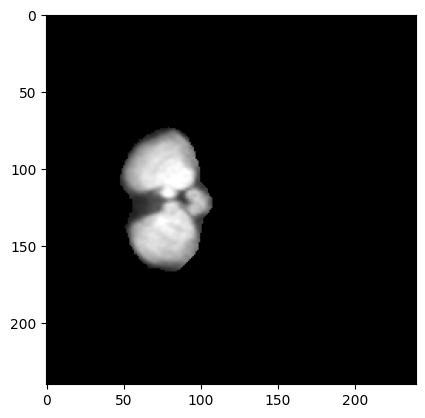

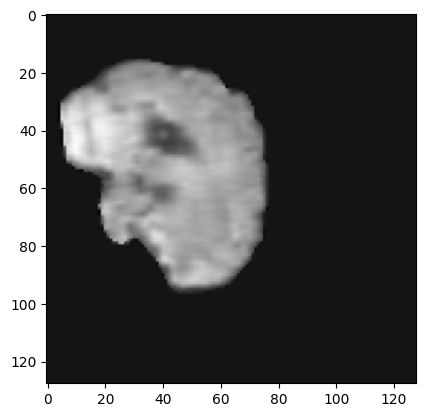

In [11]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import SimpleITK as sitk

def resample_sitk(image, target_shape, is_label=False):
    """
    Resample a 3D image using SimpleITK.

    Args:
        image (numpy.ndarray): Input 3D image.
        target_shape (tuple): Desired output shape (height, width, slices).
        is_label (bool): If True, uses nearest neighbor interpolation for segmentation masks.
    
    Returns:
        numpy.ndarray: Resampled image.
    """
    # Convert numpy array to SimpleITK image
    image_sitk = sitk.GetImageFromArray(image)

    # Get original spacing and size
    original_size = image_sitk.GetSize()  # (width, height, slices)
    original_spacing = [float(osz) / float(nsz) for osz, nsz in zip(image.shape, target_shape)]

    # Define the resampler
    resampler = sitk.ResampleImageFilter()
    resampler.SetSize(target_shape)
    resampler.SetOutputSpacing(original_spacing)
    resampler.SetInterpolator(sitk.sitkBSpline if not is_label else sitk.sitkNearestNeighbor)

    # Execute resampling
    resampled_sitk = resampler.Execute(image_sitk)

    # Convert back to numpy array
    return sitk.GetArrayFromImage(resampled_sitk)

# Define target shape
downsample_shape = (128, 128, 28)

# Define file paths
subselection = 'dwi_bet_normalized'
downsampling_method = "sitk"
SUBSELECTION_PATH = os.path.join(OUTPUT_TENSOR_PATH, f"{prestring}_{subselection}_{downsampling_method}.npz")

# Load the NIfTI image
path = all_processed_nifti_filtered[subselection][0]
img = nib.load(path).get_fdata()

# Perform resampling
resized_numpy = resample_sitk(img, downsample_shape)

resized_numpy.shape
resized_numpy = np.transpose(resized_numpy, (1, 2, 0))  # Shape: (slices, height, width)
resized_numpy.shape



img.shape
plt.imshow(img[:, :, 18], cmap='gray')
plt.show()

plt.imshow(resized_numpy[:, :, 18], cmap='gray')
plt.show()
# # Display the central slice before and after transposition
# plt.figure(figsize=(10, 5))

# # Show one slice before transposition
# plt.subplot(1, 2, 1)
# plt.imshow(resized_numpy[:, :, resized_numpy.shape[2] // 2], cmap='gray')
# plt.title("Before Transposition")

# # Transpose dimensions (move slices to the first axis)
# resized_numpy = np.transpose(resized_numpy, (2, 0, 1))  # Shape: (slices, height, width)

# # Show the same slice after transposition
# plt.subplot(1, 2, 2)
# plt.imshow(resized_numpy[resized_numpy.shape[0] // 2, :, :], cmap='gray')
# plt.title("After Transposition")

# plt.show()


# Downsamppling with Nilearn


In [ ]:
# ~ 6 mins

downsample_shape = (128, 128, 28)
subselection = 'dwi_bet_normalized'
downsampling_method = "nilearn"
prestring=f'{len(all_processed_nifti_filtered)}x{downsample_shape[0]}x{downsample_shape[1]}x{downsample_shape[2]}'
SUBSELECTION_PATH = os.path.join(OUTPUT_TENSOR_PATH, f"{prestring}_{subselection}_{downsampling_method}.npz")

def resample_nilearn(image_nifti, target_shape):
    """
    Resamples a NIfTI image to the specified target shape using nilearn.
    Args:
        image_nifti (nib.Nifti1Image): The input NIfTI image.
        target_shape (tuple): Desired output shape (height, width, slices).
    Returns:
        numpy.ndarray: The resampled image as a NumPy array.
    """
    original_affine = image_nifti.affine
    original_shape = image_nifti.shape

    # new affine transformation to match the target shape
    zoom_factors = [osz / nsz for osz, nsz in zip(original_shape, target_shape)]
    new_affine = original_affine.copy()
    new_affine[:3, :3] *= np.diag(zoom_factors)

    # Resample 
    resampled_nifti = resample_img(image_nifti, target_affine=new_affine, target_shape=target_shape, interpolation="continuous")
    return resampled_nifti.get_fdata()




patient_ids = all_processed_nifti_filtered['Patient_ID']
if not os.path.exists(SUBSELECTION_PATH):
    print('processing: ',SUBSELECTION_PATH)
    resized_patient_images = {}
    
    for i, (pid, path) in enumerate(zip(patient_ids, all_processed_nifti_filtered[subselection])):

        
        img_nifti = nib.load(path)
        resized_tensor = resample_nilearn(img_nifti, downsample_shape,interpolation="continuous",force_resample=True)
        resized_numpy = resized_tensor.squeeze()  # Shape: (128, 128, 28)
        resized_patient_images[str(pid)] = resized_numpy

    try:
        np.savez_compressed(SUBSELECTION_PATH, **resized_patient_images)
        print(f"Saved to {SUBSELECTION_PATH}")
    except Exception as e:
        print(f"Error: {e}")
    
    # Free memory
    del  patient_ids,  resized_tensor, resized_numpy
    torch.cuda.empty_cache()
    gc.collect()

# nd zoom Downsampling like Hezo in DL vs Neurologist

"Deep learning versus neurologists: functional outcome prediction in LVO stroke patients undergoing mechanical thrombectomy"

In [28]:
downsampling_method = "ndzoom"
SUBSELECTION_PATH = os.path.join(OUTPUT_TENSOR_PATH, f"{prestring}_{subselection}_{downsampling_method}.npz")

def nd_zoom(image, target_shape):
    """
    Resamples a 3D image using ndimage.zoom.

    Args:
        image (numpy.ndarray): Input 3D image.
        target_shape (tuple): Desired output shape (height, width, slices).
    
    Returns:
        numpy.ndarray: Resampled image.
    """
    # Define scaling factors
    scaling_factors = [nsz / osz for osz, nsz in zip(image.shape, target_shape)]
    return ndimage.zoom(image, scaling_factors, order=1)

patient_ids = all_processed_nifti_filtered['Patient_ID']

if not os.path.exists(SUBSELECTION_PATH):
    print('processing: ',SUBSELECTION_PATH)
    resized_patient_images = {}
    
    for i, (pid, path) in enumerate(zip(patient_ids, all_processed_nifti_filtered[subselection])):
        img_nifti = nib.load(path)
        img=img_nifti.get_fdata()
        resized_tensor = nd_zoom(img, downsample_shape)
        resized_numpy = resized_tensor.squeeze()  # Shape: (128, 128, 28)
        resized_patient_images[str(pid)] = resized_numpy

    try:
        np.savez_compressed(SUBSELECTION_PATH, **resized_patient_images)
        print(f"Saved to {SUBSELECTION_PATH}")
    except Exception as e:
        print(f"Error: {e}")
    
    # Free memory
    del  patient_ids,  resized_tensor, resized_numpy
    torch.cuda.empty_cache()
    gc.collect()

processing:  /home/bule/berner_daten_analyse/data/npz_output_tensors/413x128x128x28_dwi_bet_normalized_ndzoom.npz
Saved to /home/bule/berner_daten_analyse/data/npz_output_tensors/413x128x128x28_dwi_bet_normalized_ndzoom.npz


### check if nans exist

In [ ]:
# subselection_list=['dwi_defaced_raw', 'anatomic_defaced_raw','dwi_skull_normalized',
#                    'anatomic_skull_normalized','anatomic_defacing_mask',
#                    'anatomic_bet_mask', 'dwi_defaced_normalized','anatomic_defaced_normalized',
#                    'dwi_skull_raw', 'anatomic_skull_raw','dwi_bet_raw', 'anatomic_bet_raw',
#                    'dwi_bet_normalized','anatomic_bet_normalized']



# subselection='dwi_bet_normalized'

# downsample_shape=(128,128,28)

# prestring=f'{len(all_processed_nifti_filtered)}x{downsample_shape[0]}x{downsample_shape[1]}x{downsample_shape[2]}'
# SUBSELECTION_PATH=os.path.join(DATA_PATH,prestring+"_"+subselection+".npz")


# print('processing: ',SUBSELECTION_PATH)
# tensorlist=[]
# for path in all_processed_nifti_filtered[subselection]:
#     img = nib.load(path)
#     tensorlist.append(img.get_fdata())
# image_tensor = np.array(tensorlist)  # Shape: (425, 240, 240, 155)
# # np.isnan(tensorlist).sum()

In [ ]:
# data = np.load('/home/bule/berner_daten_analyse/data/413x128x128x28_dwi_bet_normalized.npz')
# X_in =  np.array([data[key].tolist() for key in data.files])
# np.isnan(X_in).sum()

# TABULAR DATA -------------------------------------------------------------------------------------------------

#### Original 

In [ ]:
file_path =os.path.join(DATA_PATH, 'clinical','Kopie Olea von Relevent Data Other File 20181005.xlsx')
data = pd.read_excel(file_path)

#remove the last empty rows -> these are just commentings
data = data.iloc[:578] 

print("Unique PIDs before dropping duplicates:", data['PID'].nunique())
data = data.drop_duplicates(subset='PID', keep='first')
print("Unique PIDs after dropping duplicates:", data['PID'].nunique())

data.tail(1)


In [ ]:
image_ids=set(all_processed_nifti_filtered['Patient_ID'])
rows_with_not_nan = data[~data['mRS nach 3 Monaten'].isna()]

print(len(rows_with_not_nan))
intersection_tab_img=set({int(x) for x in image_ids}).intersection(set(rows_with_not_nan['PID']))
len(intersection_tab_img)

In [ ]:
# image
selection_img=all_processed_nifti_filtered[all_processed_nifti_filtered['Patient_ID'].isin(intersection_tab_img)]
# tab
selection_tab=data[data['PID'].isin(intersection_tab_img)]

intersection_df=selection_tab.merge(selection_img, left_on='PID', right_on='Patient_ID', how='inner')
intersection_df['Datum Stroke']=pd.to_datetime(intersection_df['Datum Stroke'])
intersection_df['Date_dwi']=pd.to_datetime(intersection_df['Date_dwi'])

intersection_df['Time_difference']=intersection_df['Date_dwi']-intersection_df['Datum Stroke']
differnce=intersection_df['Time_difference']

filtered_df = intersection_df[intersection_df['Time_difference'] > pd.Timedelta(days=2)]
filtered_df.info()

In [ ]:
intersection_df['Time_difference'].apply(lambda x: x.days).value_counts()

In [ ]:
final_df = intersection_df[intersection_df['Time_difference'] < pd.Timedelta(days=2)]
print(final_df['PID'].nunique())
final_df.info()

In [ ]:
final_df.columns

In [ ]:
selected_tab=final_df[['Patient_ID','Alter  (Jahre)',
                       'Sex  0=Mann  1=Frau',
                       'NIHSS bei Eintritt',
                       'Selbständig vor Stroke: mRS 0-2: 0=nein         1=ja',
                       'PreHypert 0=nein 1=ja','RR systol bei Eintritt [mmHg]',
                       'TOAST 1=Makroangiopathie 2=kardioembolisch 3=Mikroangiopathie 4=Andere 5=ungeklärt (Abklärung komplett) 6=ungeklärt (Abklärung inkomplett) 7=Mehrere mögliche Ursachen',
                       'mRS nach 3 Monaten','PreStatin 0=nein 1=ja','Parenteral ac pre-stroke 0=nein 1=ja',
                       'Dabigatran/Pradaxa pre-stroke 0=nein 1=ja','Rivaroxaban/Xarelto pre-stroke 0=nein 1=ja',
                       'Vit. K ag pre-stroke 0=nein 1=ja','Ticagrelor pre-stroke 0=nein 1=ja','Clopidogrel pre-stroke 0=nein 1=ja'
                       ]]
selected_tab = selected_tab.rename(columns={
    'Alter  (Jahre)': 'age',
    'Sex  0=Mann  1=Frau':'sex',
    'NIHSS bei Eintritt': 'nihss',
    'Selbständig vor Stroke: mRS 0-2: 0=nein         1=ja': 'selbststaendig',
    'PreHypert 0=nein 1=ja': 'prehypert',
    'RR systol bei Eintritt [mmHg]': 'systol',
    'TOAST 1=Makroangiopathie 2=kardioembolisch 3=Mikroangiopathie 4=Andere 5=ungeklärt (Abklärung komplett) 6=ungeklärt (Abklärung inkomplett) 7=Mehrere mögliche Ursachen': 'toast',
    'PreStatin 0=nein 1=ja': 'MED_prestatin',
    'Parenteral ac pre-stroke 0=nein 1=ja': 'MED_Parenteral',
    'Dabigatran/Pradaxa pre-stroke 0=nein 1=ja': 'MED_Dabigatran_Pradaxa',
    'Rivaroxaban/Xarelto pre-stroke 0=nein 1=ja': 'MED_Rivaroxaban_Xarelto',
    'Vit. K ag pre-stroke 0=nein 1=ja': 'MED_Vit_K_ag',
    'Ticagrelor pre-stroke 0=nein 1=ja': 'MED_Ticagrelor',
    'Clopidogrel pre-stroke 0=nein 1=ja': 'MED_Clopidogrel',
    'mRS nach 3 Monaten': 'mrs'
    
})
# dichotomize outcome
selected_tab['mrs_unfavorable'] = selected_tab['mrs'].apply(lambda x: 0 if x < 3 else 1)
categorical_columns = ['selbststaendig','prehypert','systol','toast','mrs_unfavorable','MED_prestatin','MED_Parenteral',
                       'MED_Dabigatran_Pradaxa','MED_Rivaroxaban_Xarelto','MED_Vit_K_ag','MED_Ticagrelor','MED_Clopidogrel']  # List of categorical columns
selected_tab[categorical_columns] = selected_tab[categorical_columns].astype('category')
selected_tab.sort_values('Patient_ID', inplace=True, ignore_index=True)

selected_tab.info()

In [ ]:
selected_tab['mrs_unfavorable'].value_counts()

- IMPUTE

In [ ]:
selected_tab['Patient_ID'].nunique()

In [ ]:
columns_to_impute = selected_tab.columns.difference(['mrs','mrs_unfavorable'])

for col in columns_to_impute:
    if selected_tab[col].dtype.name == "category":
        selected_tab[col] = selected_tab[col].cat.codes.replace(-1, np.nan)  # Use np.nan instead of pd.NA

knn_imputer = KNNImputer(n_neighbors=10)
selected_tab[columns_to_impute] = knn_imputer.fit_transform(selected_tab[columns_to_impute])

categorical_columns = ['nihss','sex', 'selbststaendig', 'prehypert', 'systol', 'toast']
for col in categorical_columns:
    if col in selected_tab.columns:
        selected_tab[col] = pd.Categorical(selected_tab[col].round().astype(int))  # Convert back to categorical


# selected_tab.sort_values('Patient_ID', inplace=True)
selected_tab.rename(columns={'Patient_ID':'p_id'}, inplace=True)

selected_tab['p_idx']=selected_tab.index

selected_tab.to_csv(os.path.join(DATA_PATH, 'baseline_bern_test_impute_10n.csv'), index=False)

selected_tab.info()

# NORMALZIE AND Save norm file

In [ ]:
selected_tab_norm = selected_tab.copy()

transform_cols=['age','nihss','systol','toast']
selected_tab_norm[categorical_columns] = selected_tab_norm[categorical_columns].astype('int64')
# age 
selected_tab_norm['age'] = (selected_tab_norm['age'] - 0) / (110-0)
#nihss
selected_tab_norm['nihss'] = (selected_tab_norm['nihss'] - 0) / (42-0)
#systol
selected_tab_norm['systol'] = (selected_tab_norm['systol'] - 80) / (220-70)

selected_tab_norm['toast'] = selected_tab_norm['toast'].astype(int)

# Apply one-hot encoding
selected_tab_norm = pd.get_dummies(selected_tab_norm, columns=['toast'], drop_first=True)
selected_tab_norm[['toast_1', 'toast_2', 'toast_3', 'toast_4', 'toast_5']] = \
    selected_tab_norm[['toast_1', 'toast_2', 'toast_3', 'toast_4', 'toast_5']].astype(int)
    
selected_tab_norm.to_csv(os.path.join(DATA_PATH, 'baseline_bern_normalized_test.csv'), index=False)  

In [ ]:
df = selected_tab
if "mrs" not in df.columns:
    raise ValueError("Column 'mrs' not found in the dataset")

df["unfavorable"] = (df["mrs"] >= 3).astype(int)
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
df[[f'fold{i}' for i in range(10)]] = ""

# Assign folds
for fold, (train_idx, test_idx) in enumerate(skf.split(df, df["mrs"])):
    train_set, test_set = df.iloc[train_idx], df.iloc[test_idx]
    
    skf_val = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    val_size = int(0.1 * len(train_set))
    val_idx = np.random.choice(train_set.index, size=val_size, replace=False)
    val_set = train_set.loc[val_idx]
    
    df.loc[df.index.isin(test_set.index), f'fold{fold}'] = "test"
    df.loc[df.index.isin(val_set.index), f'fold{fold}'] = "val"
    df.loc[(df[f'fold{fold}'] == ""), f'fold{fold}'] = "train"

output_columns = [ "p_id", "mrs", "unfavorable"] + [f'fold{i}' for i in range(10)]

df = df[output_columns]
df['p_idx']=df.index
df.to_csv(os.path.join(DATA_PATH, '10Fold_ids_test.csv'), index=False)
df
